<a href="https://colab.research.google.com/github/suganthan-hub/Deep-learning/blob/main/1%20-%2010%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Addition:
 [[ 6  8]
 [10 12]]
Multiplication:
 [[19 22]
 [43 50]]
Transpose:
 [[1 3]
 [2 4]]


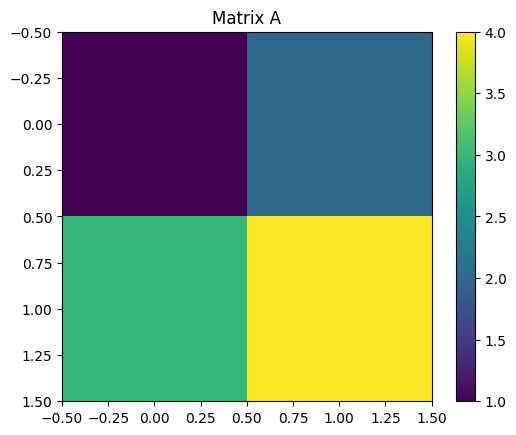

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("Addition:\n", A + B)
print("Multiplication:\n", A @ B)
print("Transpose:\n", A.T)

plt.imshow(A, cmap="viridis")
plt.colorbar()
plt.title("Matrix A")
plt.show()

Covariance:
 [[10.  13. ]
 [13.  17.3]]
Eigenvalues: [ 0.14731508 27.15268492]
Eigenvectors:
 [[-0.7969682  -0.60402127]
 [ 0.60402127 -0.7969682 ]]


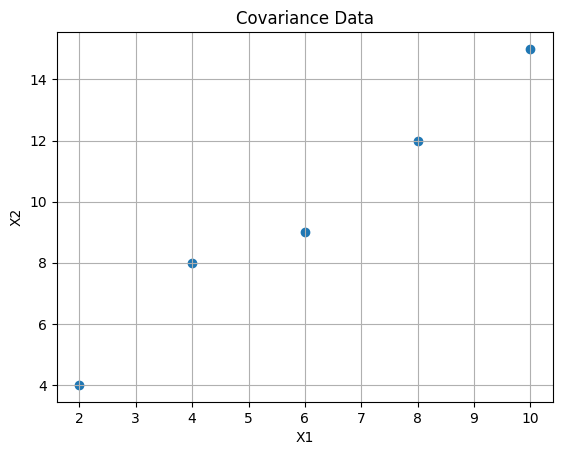

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X = np.array([[2, 4], [4, 8], [6, 9],
              [8, 12], [10, 15]])

print("Covariance:\n", np.cov(X.T))

values, vectors = np.linalg.eig(np.cov(X.T))
print("Eigenvalues:", values)
print("Eigenvectors:\n", vectors)

df = pd.DataFrame(X, columns=["X1", "X2"])
plt.scatter(df["X1"], df["X2"])
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Covariance Data")
plt.grid()
plt.show()

Posterior probability: 0.0876


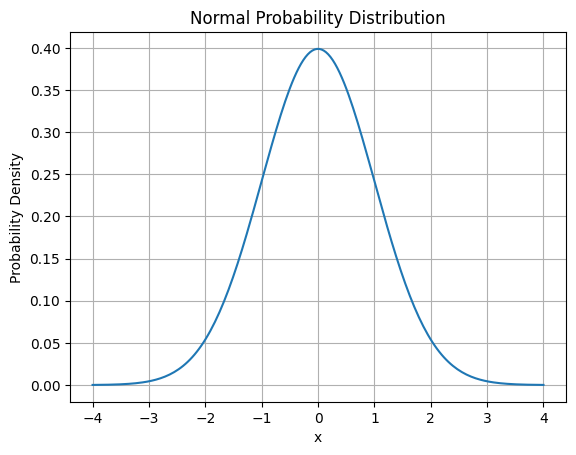

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

x = np.linspace(-4, 4, 200)
y = norm.pdf(x, 0, 1)

prevalence = 0.01
sensitivity = 0.95
specificity = 0.90

posterior = (sensitivity * prevalence) / (
    sensitivity * prevalence
    + (1 - specificity) * (1 - prevalence)
)

print("Posterior probability:", round(posterior, 4))

plt.plot(x, y)
plt.title("Normal Probability Distribution")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.grid()
plt.show()

Entropy: 0.6109
Cross-Entropy: 0.6931
KL Divergence: 0.0823


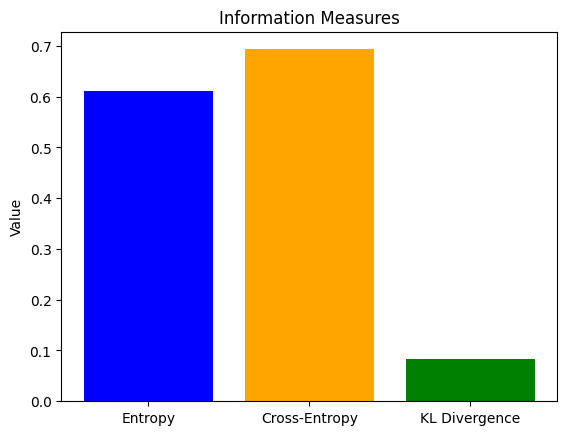

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

p = np.array([0.7, 0.3])
q = np.array([0.5, 0.5])

H = entropy(p)
CE = -np.sum(p * np.log(q))
KL = entropy(p, q)

print("Entropy:", round(H, 4))
print("Cross-Entropy:", round(CE, 4))
print("KL Divergence:", round(KL, 4))

plt.bar(["Entropy", "Cross-Entropy", "KL Divergence"],
        [H, CE, KL], color=["blue", "orange", "green"])
plt.ylabel("Value")
plt.title("Information Measures")
plt.show()

Degree 1 MSE: 0.2213
Degree 4 MSE: 0.0297
Degree 15 MSE: 0.0167


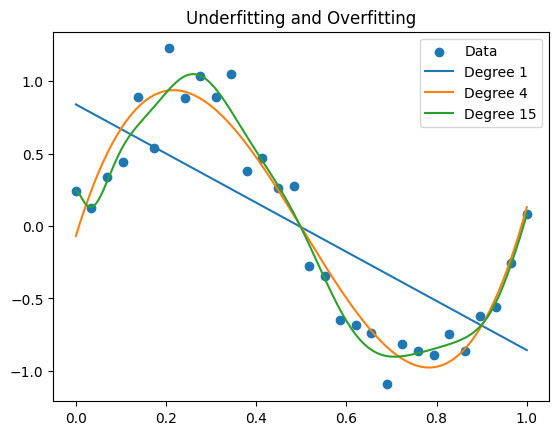

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(1)
X = np.linspace(0, 1, 30).reshape(-1, 1)
y = np.sin(2 * np.pi * X).ravel() + np.random.normal(0, 0.15, 30)

x_plot = np.linspace(0, 1, 200).reshape(-1, 1)

plt.scatter(X, y, label="Data")

for degree in [1, 4, 15]:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )
    model.fit(X, y)
    pred = model.predict(x_plot)
    print("Degree", degree,
          "MSE:", round(mean_squared_error(y, model.predict(X)), 4))
    plt.plot(x_plot, pred, label=f"Degree {degree}")

plt.legend()
plt.title("Underfitting and Overfitting")
plt.show()

Predictions: [0 0 0 1]
Actual: [0 0 0 1]


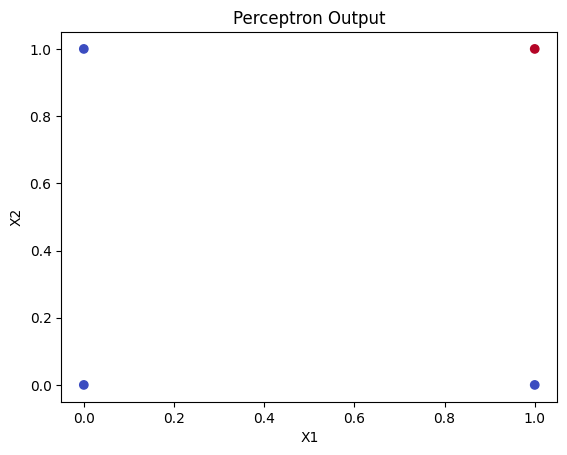

In [7]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])

w = np.array([0.5, 0.5])
b = -0.7

z = X @ w + b
pred = (z >= 0).astype(int)

print("Predictions:", pred)
print("Actual:", y)

plt.scatter(X[:, 0], X[:, 1], c=pred, cmap="coolwarm")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Perceptron Output")
plt.show()

Predictions: [0 1 1 0]


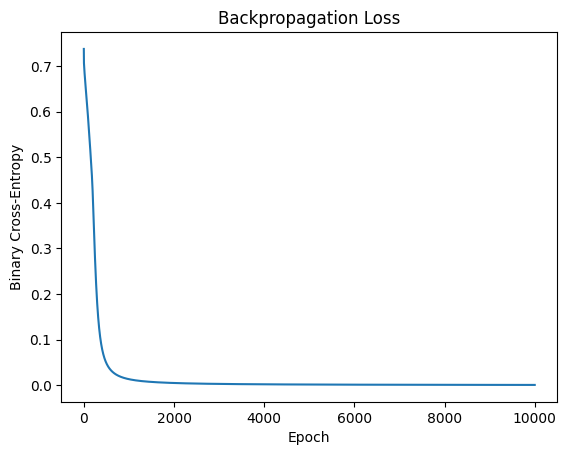

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)
X = np.array([[0,0],[0,1],[1,0],[1,1]], float)
y = np.array([[0],[1],[1],[0]], float)

sig = lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30)))
W1 = np.random.randn(2, 4)
W2 = np.random.randn(4, 1)
b1, b2 = np.zeros((1,4)), np.zeros((1,1))
losses = []

for _ in range(10000):
    h = sig(X @ W1 + b1)
    o = sig(h @ W2 + b2)
    loss = -np.mean(y*np.log(o+1e-8) + (1-y)*np.log(1-o+1e-8))
    losses.append(loss)

    do = (o-y)/len(X)
    dW2 = h.T @ do
    db2 = do.sum(axis=0, keepdims=True)
    dh = (do @ W2.T) * h * (1-h)
    dW1 = X.T @ dh
    db1 = dh.sum(axis=0, keepdims=True)

    W1 -= 1.0*dW1
    W2 -= 1.0*dW2
    b1 -= 1.0*db1
    b2 -= 1.0*db2

print("Predictions:", (o >= 0.5).astype(int).ravel())

plt.plot(losses)
plt.title("Backpropagation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.show()

Test accuracy: 0.9694444537162781


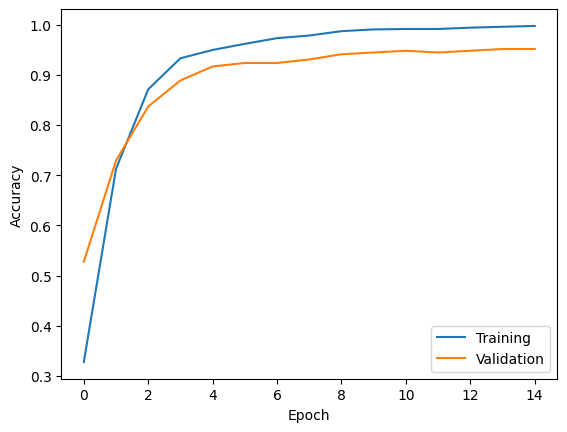

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

digits = load_digits()
X = digits.data.astype("float32")
y = digits.target

X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = keras.Sequential([
    keras.layers.Input(shape=(64,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

h = model.fit(X_train, y_train, epochs=15,
              validation_split=0.2, verbose=0)
print("Test accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])

plt.plot(h.history["accuracy"], label="Training")
plt.plot(h.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Baseline test accuracy: 0.877
L2 test accuracy: 0.873
Dropout test accuracy: 0.88
EarlyStopping test accuracy: 0.877


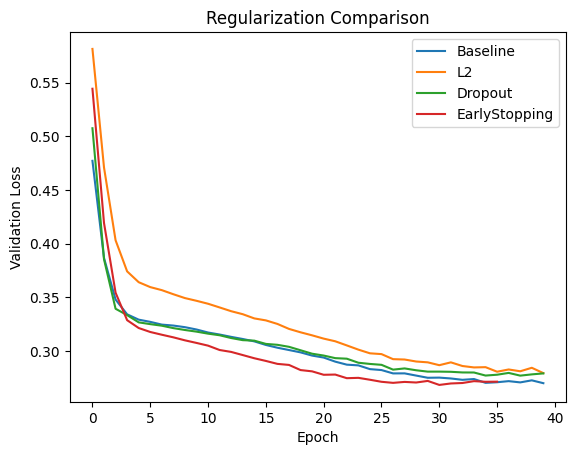

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=1200, noise=0.3, random_state=42)
X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

histories = {}

for name in ["Baseline", "L2", "Dropout", "EarlyStopping"]:
    reg = keras.regularizers.l2(0.01) if name == "L2" else None
    model = keras.Sequential([
        keras.layers.Input(shape=(2,)),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=reg),
        keras.layers.Dropout(0.3) if name == "Dropout" else keras.layers.Activation("linear"),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=["accuracy"])
    callbacks = [keras.callbacks.EarlyStopping(
        patience=5, restore_best_weights=True
    )] if name == "EarlyStopping" else []
    h = model.fit(X_train, y_train, epochs=40, batch_size=32,
                  validation_split=0.2, callbacks=callbacks, verbose=0)
    histories[name] = h.history["val_loss"]
    print(name, "test accuracy:",
          round(model.evaluate(X_test, y_test, verbose=0)[1], 3))

for name, losses in histories.items():
    plt.plot(losses, label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Regularization Comparison")
plt.legend()
plt.show()